# Mixed-precision training, explained from scratch ⚖️
### Do the heavy maths in a cheap number format, keep the important bookkeeping in a precise one

In the previous notebook (`01_number_formats_datatypes`) we saw that **fp16 / bf16 are small and fast but blurry**, while **fp32 is big and precise**. *Mixed-precision training* is the recipe that gets most of the speed and memory benefit of the small formats **without** the training falling apart.

> **In one sentence:** keep a precise (fp32) *master copy* of the weights, run the expensive forward/backward passes on a cheap (fp16/bf16) *working copy*, and fix the three things that go wrong with cheap numbers.

| step | what you will see |
|---|---|
| 1 | the idea in plain words (an analogy) and **one training step as a diagram** |
| 2 | **animation**: the diagram running, stage by stage |
| 3 | problem 1 - tiny weight updates get lost → *fp32 master weights* (**animation**) |
| 4 | problem 2 - tiny gradients vanish → *loss scaling* (measured on a deep network) |
| 5 | the scaler that adapts itself: *dynamic loss scaling* (built, then **verified against PyTorch's `GradScaler`**, **animation**) |
| 6 | problem 3 - some operations must stay fp32 → what `torch.autocast` does (measured) |
| 7 | putting it together: train one network four ways and compare |
| 8 | what it saves (and what it does **not**): memory, measured |
| 9 | **PyTorch recipes** - copy-paste code, each one executed here |

*Prerequisite:* know what fp32 / fp16 / bf16 mean (see notebook 01, Steps 3-7). CPU only; every claim is checked in a cell (`PASS` lines, summary table at the end).

In [1]:
import math, io, copy, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle
from PIL import Image as PILImage
from IPython.display import Image, display

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
ASSETS = Path("../../assets/numerics").resolve(); ASSETS.mkdir(parents=True, exist_ok=True)
HI_C, LO_C = "#1c7ed6", "#e8590c"        # blue = precise (fp32) lane, orange = cheap (fp16/bf16) lane, used everywhere
GOOD_C, BAD_C = "#2f9e44", "#c92a2a"

CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append((name, bool(ok), detail))
    print(("PASS" if ok else "FAIL"), "-", name, ("| " + detail) if detail else "")

def fig_png(fig, dpi=80):
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=dpi); plt.close(fig); return buf.getvalue()

def save_gif(frames, path, ms=140, hold_last=900):
    imgs = [PILImage.open(io.BytesIO(b)).convert("RGB").convert("P", palette=PILImage.ADAPTIVE, colors=128) for b in frames]
    dur = [ms] * len(imgs); dur[-1] = hold_last
    imgs[0].save(path, save_all=True, append_images=imgs[1:], duration=dur, loop=0, optimize=True, disposal=2)
    return path
print("torch", torch.__version__)

torch 2.14.1


## Step 1 - The idea, in plain words

**An analogy.** An accountant keeps the *official ledger* in exact figures (fp32). For quick scratch work she uses a cheap pocket calculator that only shows 3 digits (fp16 / bf16). Two things would go wrong if she did *everything* on the calculator:

1. A tiny daily deposit of 0.0001 added to a balance of 1.000 does nothing on the 3-digit display - after a year the balance never moved. → **keep the ledger exact**, only copy numbers to the calculator when you need to compute.
2. Some numbers are so small the calculator shows 0. → **multiply them up first**, calculate, then divide back down.

That is the whole technique. Here it is as one training step:

| in a normal (fp32) step | in a mixed-precision step |
|---|---|
| weights fp32 | **master** weights fp32 + a **cheap copy** in fp16/bf16 |
| forward & backward in fp32 | forward & backward on the *cheap copy* (this is ~all the compute) |
| loss fp32 | loss still fp32 |
| optimizer updates the weights | optimizer updates the **fp32 master**, then the copy is refreshed |
| - | gradients are multiplied by a scale `S` for backward and divided again afterwards (fp16 only) |

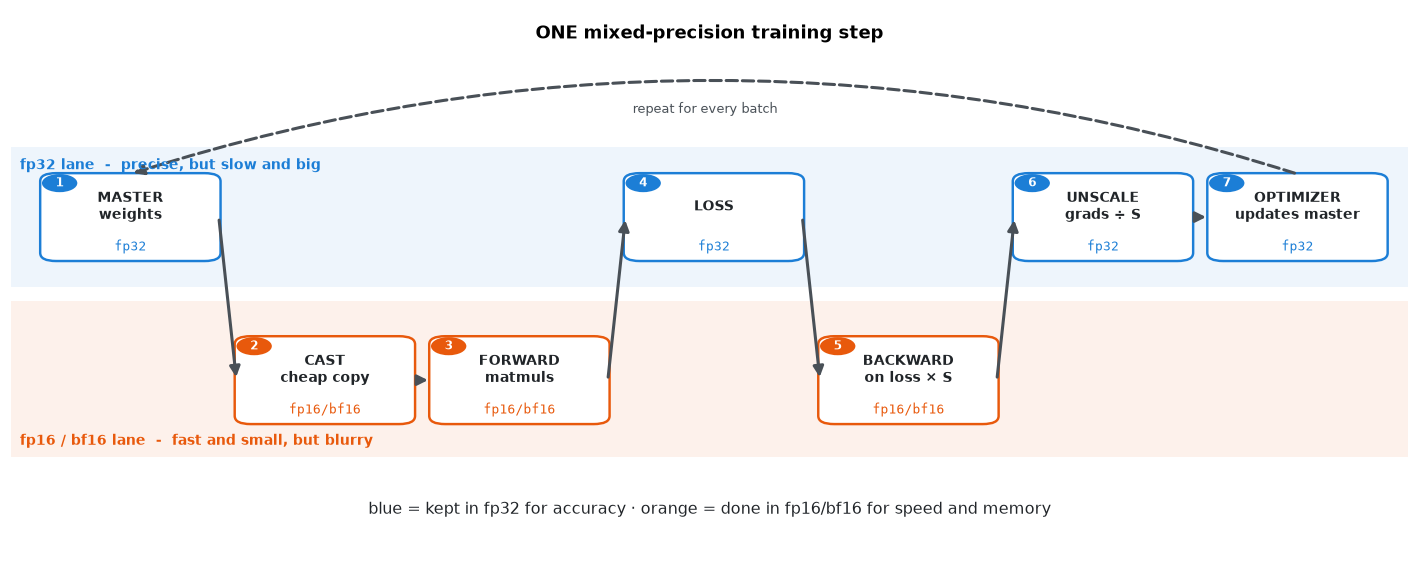

In [2]:
# Seven stages of one mixed-precision step. lane: "hi" = fp32, "lo" = fp16/bf16
STAGES = [
    ("1", "hi", "MASTER\nweights", "fp32"),
    ("2", "lo", "CAST\ncheap copy", "fp16/bf16"),
    ("3", "lo", "FORWARD\nmatmuls", "fp16/bf16"),
    ("4", "hi", "LOSS", "fp32"),
    ("5", "lo", "BACKWARD\non loss × S", "fp16/bf16"),
    ("6", "hi", "UNSCALE\ngrads ÷ S", "fp32"),
    ("7", "hi", "OPTIMIZER\nupdates master", "fp32"),
]
CAPTIONS = [
    "1  Keep one precise copy of every weight in fp32: the MASTER. It is the only thing that is ever 'saved'.",
    "2  Make a cheap fp16/bf16 copy of the weights (half the bytes) for the heavy work.",
    "3  FORWARD: the big matrix multiplies run on the cheap copy - fast and small.",
    "4  The LOSS (a sum over many values) is computed in fp32 where the accuracy is.",
    "5  BACKWARD: the loss is first multiplied by S so tiny gradients do not vanish in fp16 (bf16: S = 1).",
    "6  UNSCALE: gradients are cast to fp32 and divided by S. If any is inf/NaN the whole step is skipped.",
    "7  The OPTIMIZER updates the fp32 MASTER - tiny updates are kept. Then back to step 2 with the new weights.",
]
BX = [0.35 + i * 2.2 for i in range(7)]; BW = 2.0; BH = 1.9; YHI, YLO = 4.5, 0.9

def draw_flow(ax, active=None, title=None):
    ax.set_xlim(0, 15.8); ax.set_ylim(-1.9, 10.0); ax.axis("off")
    ax.add_patch(Rectangle((0.0, 3.9), 15.8, 3.1, fc=HI_C, alpha=0.07, ec="none"))
    ax.add_patch(Rectangle((0.0, 0.15), 15.8, 3.45, fc=LO_C, alpha=0.08, ec="none"))
    ax.text(0.1, 6.75, "fp32 lane  -  precise, but slow and big", color=HI_C, fontsize=9, fontweight="bold", va="top")
    ax.text(0.1, 0.35, "fp16 / bf16 lane  -  fast and small, but blurry", color=LO_C, fontsize=9, fontweight="bold", va="bottom")
    boxes = []
    for i, (num, lane, label, dt) in enumerate(STAGES):
        y = YHI if lane == "hi" else YLO; col = HI_C if lane == "hi" else LO_C
        on = active is None or active == i
        a = 1.0 if on else 0.35
        ax.add_patch(FancyBboxPatch((BX[i], y), BW, BH, boxstyle="round,pad=0.02,rounding_size=0.18", fc="white", ec=col, lw=3.2 if (active == i) else 1.6, alpha=a))
        ax.text(BX[i] + BW / 2, y + BH * 0.62, label, ha="center", va="center", fontsize=9, fontweight="bold", color="#212529", alpha=a)
        ax.text(BX[i] + BW / 2, y + 0.3, dt, ha="center", va="center", fontsize=8.5, color=col, alpha=a, family="monospace")
        ax.add_patch(plt.Circle((BX[i] + 0.2, y + BH - 0.2), 0.2, fc=col, ec="none", alpha=a))
        ax.text(BX[i] + 0.2, y + BH - 0.2, num, color="white", ha="center", va="center", fontsize=8, fontweight="bold", alpha=a)
        boxes.append((y, col))
    for i in range(6):
        y0 = boxes[i][0] + BH / 2; y1 = boxes[i + 1][0] + BH / 2
        on = active is None or active in (i, i + 1)
        ax.add_patch(FancyArrowPatch((BX[i] + BW, y0), (BX[i + 1], y1), arrowstyle="-|>", mutation_scale=14, lw=2 if on else 1, color="#495057", alpha=1 if on else 0.3))
    ax.add_patch(FancyArrowPatch((BX[6] + BW / 2, YHI + BH), (BX[0] + BW / 2, YHI + BH), connectionstyle="arc3,rad=0.16", arrowstyle="-|>", mutation_scale=14,
                                 lw=2 if (active in (None, 6, 0)) else 1, color="#495057", alpha=1 if active in (None, 6, 0) else 0.3, linestyle="--"))
    ax.text(BX[3] + 0.9, 7.75, "repeat for every batch", ha="center", fontsize=8.5, color="#495057")
    if active is not None:
        ax.text(7.9, -1.1, CAPTIONS[active], ha="center", va="center", fontsize=10.5, color="#212529",
                bbox=dict(boxstyle="round,pad=0.5", fc="#f8f9fa", ec="#ced4da"))
    if title: ax.text(7.9, 9.5, title, ha="center", va="center", fontsize=12, fontweight="bold")

fig, ax = plt.subplots(figsize=(13, 5.2)); draw_flow(ax, None, "ONE mixed-precision training step")
ax.text(7.9, -1.1, "blue = kept in fp32 for accuracy · orange = done in fp16/bf16 for speed and memory", ha="center", fontsize=10.5, color="#212529")
plt.tight_layout(); plt.show()

Read it left to right: master weights → cheap copy → forward → loss → backward → unscale → update the master. **Only the orange boxes are the expensive ones** (they contain all the big matrix multiplications), and those are the ones moved to the cheap format. Everything blue is small or delicate and stays precise.

## Step 2 - Animation: the step running, stage by stage

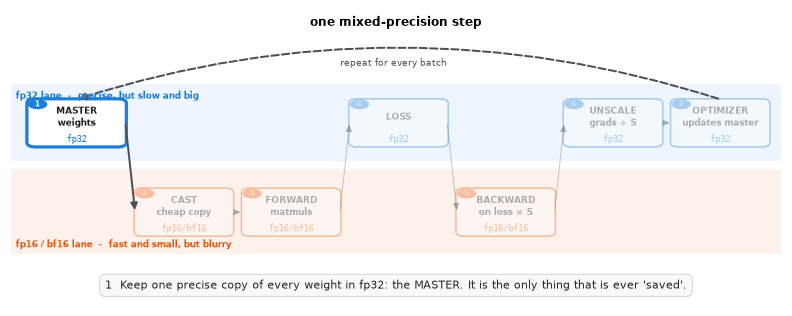

PASS - animation 1 written (14 frames) | 133 KB


In [3]:
frames = []
for rep in range(1):
    for i in range(7):
        for _ in range(2):
            fig, ax = plt.subplots(figsize=(11, 4.4)); draw_flow(ax, i, "one mixed-precision step"); plt.tight_layout()
            frames.append(fig_png(fig, 72))
gif1 = save_gif(frames, ASSETS / "mixed_precision_step.gif", ms=650, hold_last=1500)
display(Image(filename=str(gif1)))
check("animation 1 written (14 frames)", gif1.exists() and gif1.stat().st_size > 20_000, f"{gif1.stat().st_size / 1024:.0f} KB")

Now the three questions that make this *work* instead of just *run*. Each problem is real - we reproduce it, then show the fix.

## Step 3 - Problem 1: tiny weight updates are lost → keep **fp32 master weights**

Training adds many tiny updates to a weight: `w ← w − lr·gradient`. A typical update (say `1e-4`) is *much smaller than the gap between neighbouring fp16 numbers around 1.0* (≈ 0.001, from `eps = 2⁻¹⁰`, notebook 01 Step 4). The addition is **rounded away**.

Experiment: one weight `w = 1.0`, apply `3000` updates of `+1e-4`. The true answer is `1.3`.

In [4]:
STEPS_N, UPD = 3000, 1e-4
# (a) weight stored only in fp16:   w <- w + upd, rounded to fp16 every step
w16 = torch.tensor(1.0, dtype=torch.float16); upd16 = torch.tensor(UPD, dtype=torch.float16); pure = [1.0]
for _ in range(STEPS_N):
    w16 = w16 + upd16; pure.append(w16.item())
# (b) fp32 master + fp16 working copy rounded from it
master = 1.0 + UPD * np.arange(STEPS_N + 1, dtype=np.float64)                     # exact, what the fp32 master would hold
master32 = (torch.tensor(1.0, dtype=torch.float32) + torch.arange(STEPS_N + 1, dtype=torch.float32) * UPD).numpy()
copy16 = torch.tensor(master32).half().double().numpy()
pure = np.array(pure)
print(f"after {STEPS_N} updates of +{UPD:g}:   true 1.3000 | fp16 only {pure[-1]:.4f} | fp32 master {master32[-1]:.4f} | its fp16 copy {copy16[-1]:.4f}")
check("fp16-only weight never moves (updates rounded away)", pure[-1] == 1.0, f"final {pure[-1]}")
check("fp32 master reaches 1.3 (<1e-4 error)", abs(master32[-1] - 1.3) < 1e-4, f"final {master32[-1]:.5f}")
check("the fp16 copy follows the master to within half an fp16 step (<=2^-11 * 2)", np.abs(copy16 - master32).max() <= 2 ** -10 * 1.01, f"max gap {np.abs(copy16 - master32).max():.2e}")

after 3000 updates of +0.0001:   true 1.3000 | fp16 only 1.0000 | fp32 master 1.3000 | its fp16 copy 1.2998
PASS - fp16-only weight never moves (updates rounded away) | final 1.0
PASS - fp32 master reaches 1.3 (<1e-4 error) | final 1.30000
PASS - the fp16 copy follows the master to within half an fp16 step (<=2^-11 * 2) | max gap 4.88e-04


Animation of exactly this: **left** the whole run, **right** a zoom on the first 40 updates. The *master* climbs smoothly; its fp16 *copy* is a staircase that hops each time the master passes the halfway point to the next fp16 number; the **fp16-only** weight stays frozen.

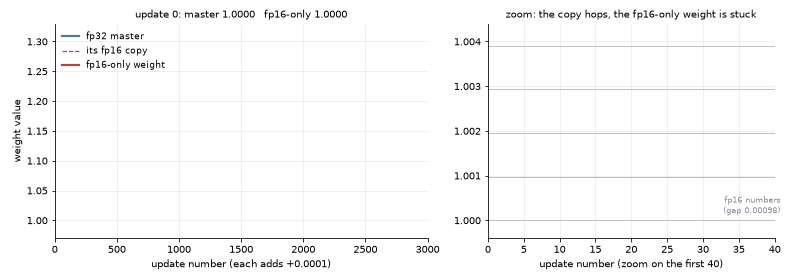

PASS - animation 2 written | 554 KB


In [5]:
ulp = 2.0 ** -10
frames = []
NF = 30
for f in range(NF + 1):
    t = int(round(STEPS_N * f / NF)); tz = int(round(40 * f / NF))
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.9), gridspec_kw={"width_ratios": [1.3, 1]})
    ax = axs[0]
    ax.plot(np.arange(t + 1), master32[:t + 1], color=HI_C, lw=2.2, label="fp32 master")
    ax.plot(np.arange(t + 1), copy16[:t + 1], color=LO_C, lw=1.2, ls="--", label="its fp16 copy")
    ax.plot(np.arange(t + 1), pure[:t + 1], color=BAD_C, lw=2.2, label="fp16-only weight")
    ax.set_xlim(0, STEPS_N); ax.set_ylim(0.97, 1.33); ax.set_xlabel("update number (each adds +0.0001)"); ax.set_ylabel("weight value")
    ax.legend(loc="upper left", frameon=False, fontsize=8.5); ax.set_title(f"update {t}: master {master32[t]:.4f}   fp16-only {pure[t]:.4f}", fontsize=10)
    ax = axs[1]
    for k in range(0, 5): ax.axhline(1 + k * ulp, color="#adb5bd", lw=0.8)
    ax.text(40.8, 1 + ulp / 2 * 0.2, "fp16 numbers\n(gap 0.00098)", fontsize=7.5, color="#868e96", va="bottom", ha="right")
    ax.plot(np.arange(tz + 1), master32[:tz + 1], color=HI_C, lw=2.2)
    ax.step(np.arange(tz + 1), copy16[:tz + 1], where="post", color=LO_C, lw=2)
    ax.plot(np.arange(tz + 1), pure[:tz + 1], color=BAD_C, lw=2.2)
    ax.set_xlim(0, 40); ax.set_ylim(0.9996, 1.0044); ax.set_xlabel("update number (zoom on the first 40)"); ax.set_title("zoom: the copy hops, the fp16-only weight is stuck", fontsize=10)
    plt.tight_layout(); frames.append(fig_png(fig, 72))
gif2 = save_gif(frames, ASSETS / "master_weights_vs_fp16_only.gif", ms=120, hold_last=1800)
display(Image(filename=str(gif2)))
check("animation 2 written", gif2.exists(), f"{gif2.stat().st_size / 1024:.0f} KB")

**Fix 1 - fp32 master weights.** The optimizer (SGD/Adam and its moment buffers) works on the fp32 master, so every tiny update is kept. After each step the cheap copy is refreshed from the master. This is also why the *optimizer state* does **not** get smaller in mixed precision (Step 8).

Does it matter in a real network? A last check on the "optimizer in pure fp16" idea - Adam's default `eps = 1e-8` cannot even exist in fp16:

In [6]:
print("1e-8 in fp16 =", torch.tensor(1e-8).half().item(), "   (Adam's epsilon becomes 0)")
print("(1e-4)^2 in fp16 =", (torch.tensor(1e-4).half() ** 2).item(), "   (Adam's second-moment of a gradient 1e-4 becomes 0)")
check("Adam eps=1e-8 is 0 in fp16, and a squared 1e-4 gradient underflows", torch.tensor(1e-8).half().item() == 0.0 and (torch.tensor(1e-4).half() ** 2).item() == 0.0)

1e-8 in fp16 = 0.0    (Adam's epsilon becomes 0)
(1e-4)^2 in fp16 = 0.0    (Adam's second-moment of a gradient 1e-4 becomes 0)
PASS - Adam eps=1e-8 is 0 in fp16, and a squared 1e-4 gradient underflows 


Adam divides by `sqrt(v) + eps`; with both `v` and `eps` flushed to 0 that is `0/0 = NaN`. We will see this happen in Step 7.

## Step 4 - Problem 2: tiny gradients vanish → **loss scaling**

fp16 cannot represent anything below `6e-8` and loses precision already below `6e-5` (its *subnormal* zone, notebook 01). Gradients in deep networks - especially in **early layers** and **late in training** - are often that small. If a gradient is flushed to `0`, that weight silently stops learning.

**Fix 2 - loss scaling.** Backprop is linear: multiply the loss by `S` and *every* gradient is multiplied by `S`. Choose `S` (e.g. 4096) so they land in fp16's comfortable zone, do the backward pass, then **divide by `S` in fp32** to recover the true gradient.

Measured on a 12-layer tanh network run entirely in fp16. "late in training" is mimicked by multiplying the loss by `1e-3` (gradients shrink as the model fits the data):

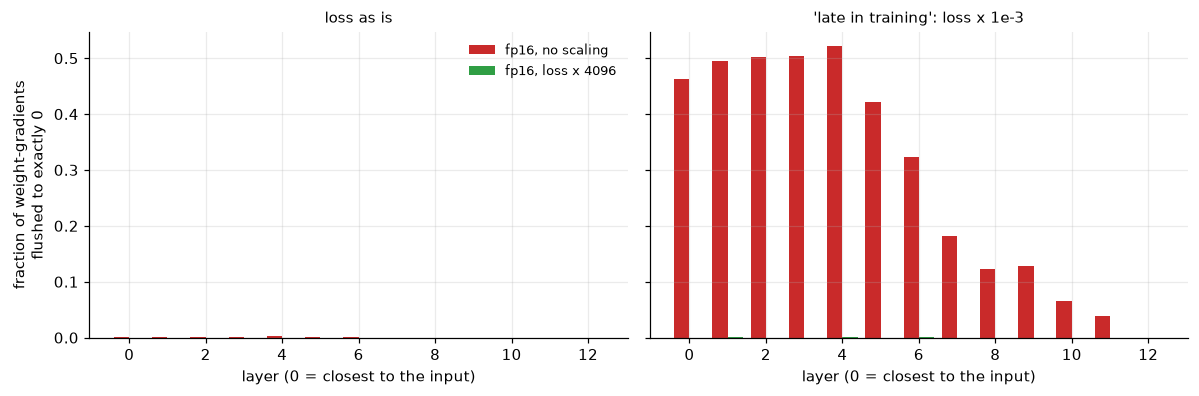

loss x 1: zeroed grads (mean over layers)  plain 0.1%  scaled 0.0%  |  mean relative gradient error vs fp32  plain 0.001  scaled 0.0009
loss x 0.001: zeroed grads (mean over layers)  plain 29.0%  scaled 0.0%  |  mean relative gradient error vs fp32  plain 0.277  scaled 0.0010
PASS - fp32 reference has no zeroed gradients 
PASS - late-training case: >20% of fp16 gradients are flushed to 0 without scaling | 29.0%
PASS - loss scaling removes almost all of them (<2%) and stays finite | 0.01%
PASS - and gradient error vs fp32 drops by >5x | 0.277 -> 0.0010


In [7]:
def deep_net(d=64, L=12, seed=0):
    torch.manual_seed(seed)
    return nn.Sequential(*[nn.Sequential(nn.Linear(d, d), nn.Tanh()) for _ in range(L)], nn.Linear(d, 1))

def layer_grads(loss_factor, S, low=torch.float16):
    net32 = deep_net(); torch.manual_seed(1); x = torch.randn(32, 64); y = torch.randn(32, 1)
    l = nn.functional.mse_loss(net32(x), y) * loss_factor; l.backward()
    g32 = [(m[0] if isinstance(m, nn.Sequential) else m).weight.grad.clone() for m in net32]
    net = copy.deepcopy(net32).to(low); net.zero_grad()
    l = nn.functional.mse_loss(net(x.to(low)).float(), y) * loss_factor * S
    l.backward()
    g = [((m[0] if isinstance(m, nn.Sequential) else m).weight.grad.float() / S) for m in net]    # unscale in fp32
    return g32, g

S = 4096.0
fig, axs = plt.subplots(1, 2, figsize=(11, 3.7), sharey=True)
res = {}
for ax, (title, lf) in zip(axs, [("loss as is", 1.0), ("'late in training': loss x 1e-3", 1e-3)]):
    g32, g_plain = layer_grads(lf, 1.0); _, g_scaled = layer_grads(lf, S)
    z_plain = [(g == 0).float().mean().item() for g in g_plain]; z_scaled = [(g == 0).float().mean().item() for g in g_scaled]
    z_ref = [(g == 0).float().mean().item() for g in g32]
    relerr = lambda g: np.mean([((a - b).norm() / b.norm()).item() for a, b in zip(g, g32)])
    res[lf] = dict(plain=z_plain, scaled=z_scaled, ref=z_ref, err_plain=relerr(g_plain), err_scaled=relerr(g_scaled), fin=all(torch.isfinite(g).all() for g in g_scaled))
    ax.bar(np.arange(13) - 0.2, z_plain, 0.4, color=BAD_C, label="fp16, no scaling"); ax.bar(np.arange(13) + 0.2, z_scaled, 0.4, color=GOOD_C, label=f"fp16, loss x {int(S)}")
    ax.set_title(title, fontsize=10); ax.set_xlabel("layer (0 = closest to the input)"); ax.set_xticks(range(0, 13, 2))
axs[0].set_ylabel("fraction of weight-gradients\nflushed to exactly 0"); axs[0].legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()
for lf, r in res.items():
    print(f"loss x {lf:g}: zeroed grads (mean over layers)  plain {np.mean(r['plain']):.1%}  scaled {np.mean(r['scaled']):.1%}  |  mean relative gradient error vs fp32  plain {r['err_plain']:.3f}  scaled {r['err_scaled']:.4f}")
r = res[1e-3]
check("fp32 reference has no zeroed gradients", max(r["ref"]) == 0.0)
check("late-training case: >20% of fp16 gradients are flushed to 0 without scaling", np.mean(r["plain"]) > 0.20, f"{np.mean(r['plain']):.1%}")
check("loss scaling removes almost all of them (<2%) and stays finite", np.mean(r["scaled"]) < 0.02 and r["fin"], f"{np.mean(r['scaled']):.2%}")
check("and gradient error vs fp32 drops by >5x", r["err_plain"] > 5 * r["err_scaled"], f"{r['err_plain']:.3f} -> {r['err_scaled']:.4f}")

**Which `S`?** Too small and gradients still underflow; too large and `S × gradient` **overflows** past 65 504 to `inf`. The best value changes during training. So frameworks adapt it automatically:

## Step 5 - Dynamic loss scaling

The rule (this is what PyTorch's `GradScaler` does):
1. start with a large `S` (2¹⁶);
2. after backward, **check the gradients for `inf`/`NaN`**. If found: **skip this optimizer step** and halve `S`;
3. if `N` steps in a row were fine: **double `S`** (probe upward again).

So `S` hovers just below the overflow edge - as large as safely possible. Let me write it (8 lines) and **verify it against PyTorch's `GradScaler`** on a scripted pattern of good and bad (`inf`) steps:

In [8]:
class DynamicScaler:
    """Dynamic loss scaling: halve on inf/NaN (and skip the step), double after `interval` clean steps."""
    def __init__(self, init=2.0 ** 16, growth=2.0, backoff=0.5, interval=2000):
        self.scale, self.growth, self.backoff, self.interval, self.good = init, growth, backoff, interval, 0
    def update(self, found_inf):
        if found_inf: self.scale *= self.backoff; self.good = 0
        else:
            self.good += 1
            if self.good == self.interval: self.scale *= self.growth; self.good = 0

pattern = [0] * 7 + [1] + [0] * 3 + [1, 1] + [0] * 12 + [1] + [0] * 6        # 1 = this step's gradients contain inf
ours = DynamicScaler(interval=5); sc = torch.amp.GradScaler("cpu", init_scale=2.0 ** 16, growth_interval=5)
w = torch.nn.Parameter(torch.zeros(1)); opt = torch.optim.SGD([w], lr=0.1)
ours_trace, torch_trace, stepped = [], [], []
for bad in pattern:
    gv = torch.tensor([float("inf") if bad else 1.0])
    opt.zero_grad(); before = w.item()
    sc.scale((w * gv).sum()).backward(); sc.step(opt); sc.update()
    stepped.append(w.item() != before)
    ours.update(bool(bad)); ours_trace.append(ours.scale); torch_trace.append(sc.get_scale())
print("scale after each step (ours) :", [int(math.log2(s)) for s in ours_trace], " (log2)")
print("scale after each step (torch):", [int(math.log2(s)) for s in torch_trace])
check("our DynamicScaler reproduces torch GradScaler's scale on 30 scripted steps", ours_trace == torch_trace)
check("torch skipped the optimizer step exactly on the inf steps", stepped == [not b for b in pattern])

scale after each step (ours) : [16, 16, 16, 16, 17, 17, 17, 16, 16, 16, 16, 15, 14, 14, 14, 14, 14, 15, 15, 15, 15, 15, 16, 16, 16, 15, 15, 15, 15, 15, 16, 16]  (log2)
scale after each step (torch): [16, 16, 16, 16, 17, 17, 17, 16, 16, 16, 16, 15, 14, 14, 14, 14, 14, 15, 15, 15, 15, 15, 16, 16, 16, 15, 15, 15, 15, 15, 16, 16]
PASS - our DynamicScaler reproduces torch GradScaler's scale on 30 scripted steps 
PASS - torch skipped the optimizer step exactly on the inf steps 


Same behaviour, so the 8-line version *is* the algorithm. Now watch it work. The simulated run below has gradients that **grow** during training, so the safe `S` keeps shrinking. `S` starts far too large: `S × gradient` exceeds fp16's maximum (red line), the step overflows and is **skipped**, `S` halves, and this repeats until `S` sits just under the edge. After that it keeps probing upward every 20 clean steps (a few more skips).

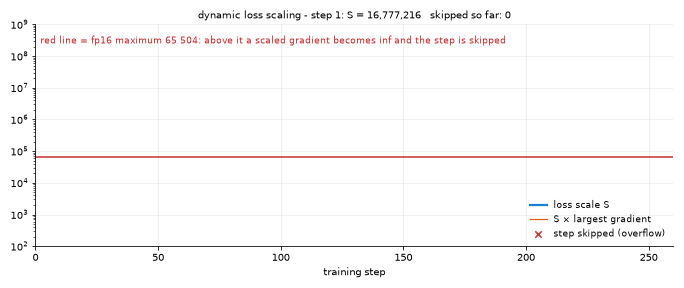

PASS - scaled gradients never overflow on a step that was actually applied 
PASS - only a small fraction of steps are skipped (<15%) | 15 of 260 skipped
PASS - S follows the shrinking safe value down by >4x (it adapts) | 16777216 -> 249037


In [9]:
FP16_MAX = 65504.0
T = 260; t_ax = np.arange(T)
gmax = 10 ** np.interp(t_ax, [0, T], [-2.6, -0.6]) * (1 + 0.15 * np.sin(t_ax / 5))      # largest true gradient in the batch, growing
sim = DynamicScaler(init=2.0 ** 24, interval=20); S_hist, skipped, scaled_max = [], [], []
for t in range(T):
    scaled = gmax[t] * sim.scale; inf = scaled > FP16_MAX
    S_hist.append(sim.scale); scaled_max.append(min(scaled, FP16_MAX * 4)); skipped.append(inf); sim.update(inf)
S_hist, skipped, scaled_max = np.array(S_hist), np.array(skipped), np.array(scaled_max)

frames = []
for f in range(0, T + 1, 10):
    fig, ax = plt.subplots(figsize=(9.5, 4.0))
    t = max(f, 1)
    ax.axhline(FP16_MAX, color=BAD_C, lw=1.5); ax.text(2, 2.5e8, "red line = fp16 maximum 65 504: above it a scaled gradient becomes inf and the step is skipped", color=BAD_C, fontsize=8.5)
    ax.step(t_ax[:t], S_hist[:t], where="post", color=HI_C, lw=2.2, label="loss scale S")
    ax.plot(t_ax[:t], scaled_max[:t], color=LO_C, lw=1.2, label="S × largest gradient")
    ax.scatter(t_ax[:t][skipped[:t]], scaled_max[:t][skipped[:t]], marker="x", color=BAD_C, s=40, zorder=5, label="step skipped (overflow)")
    ax.set_yscale("log"); ax.set_xlim(0, T); ax.set_ylim(1e2, 1e9); ax.set_xlabel("training step")
    ax.set_title(f"dynamic loss scaling - step {t}: S = {S_hist[t - 1]:,.0f}   skipped so far: {int(skipped[:t].sum())}", fontsize=10)
    ax.legend(loc="lower right", frameon=False, fontsize=8.5)
    plt.tight_layout(); frames.append(fig_png(fig, 72))
gif3 = save_gif(frames, ASSETS / "dynamic_loss_scaling.gif", ms=170, hold_last=1800)
display(Image(filename=str(gif3)))
ok_after = ~skipped
check("scaled gradients never overflow on a step that was actually applied", (gmax[ok_after] * S_hist[ok_after] <= FP16_MAX).all())
check("only a small fraction of steps are skipped (<15%)", skipped.mean() < 0.15, f"{skipped.sum()} of {T} skipped")
check("S follows the shrinking safe value down by >4x (it adapts)", S_hist[:20].mean() > 4 * S_hist[-20:].mean(), f"{S_hist[:20].mean():.0f} -> {S_hist[-20:].mean():.0f}")

**bf16 needs none of this.** It has fp32's exponent range, so gradients do not underflow/overflow: no `S`, no skipping, no `GradScaler`. That is the main reason bf16 became the default where it is supported (precision is what it gives up, notebook 01 Step 6).

## Step 6 - Problem 3: some operations must stay in fp32 → what `autocast` does

You do **not** convert operations to fp16 by hand. `torch.autocast` picks a dtype **per operation**: matrix multiplies and convolutions (compute-heavy, tolerant) go low; reductions, losses and exponentials (precision-sensitive, cheap) stay fp32. We can measure its choices rather than trust a list - feed fp32 tensors through each operation under `autocast(bf16)` and see what comes out:

In [10]:
x = torch.randn(8, 16); W_ = torch.randn(16, 16); b_ = torch.randn(16); ln = nn.LayerNorm(16); y_ = torch.randn(8, 16)
ops = {
    "linear (matmul)":        lambda: torch.nn.functional.linear(x, W_, b_),
    "matmul":                 lambda: x @ W_,
    "relu":                   lambda: torch.relu(x),
    "add":                    lambda: x + y_,
    "layer_norm":             lambda: ln(x),
    "softmax":                lambda: torch.softmax(x, -1),
    "exp":                    lambda: torch.exp(x),
    "sum (reduction)":        lambda: x.sum(),
    "mse_loss":               lambda: torch.nn.functional.mse_loss(x, y_),
}
rows = []
with torch.autocast("cpu", dtype=torch.bfloat16):
    for k, f in ops.items(): rows.append((k, f().dtype))
print(f"{'operation':18s} output dtype under autocast(bfloat16) given fp32 inputs   [{'LOW' }= bf16]")
for k, dt in rows: print(f"{k:18s} {str(dt):16s} {'<- LOW' if dt == torch.bfloat16 else ''}")
d = dict(rows)
check("matmul/linear are autocast to bf16 (the expensive ops)", d["linear (matmul)"] == torch.bfloat16 and d["matmul"] == torch.bfloat16)
check("loss and reductions stay fp32", d["mse_loss"] == torch.float32 and d["sum (reduction)"] == torch.float32)

operation          output dtype under autocast(bfloat16) given fp32 inputs   [LOW= bf16]
linear (matmul)    torch.bfloat16   <- LOW
matmul             torch.bfloat16   <- LOW
relu               torch.float32    
add                torch.float32    
layer_norm         torch.float32    
softmax            torch.float32    
exp                torch.float32    
sum (reduction)    torch.float32    
mse_loss           torch.float32    
PASS - matmul/linear are autocast to bf16 (the expensive ops) 
PASS - loss and reductions stay fp32 


This is **the CPU list**; the CUDA list is similar but not identical (the PyTorch docs give the per-device lists). The pattern is the point: **heavy, tolerant ops → low precision; accuracy-critical ops → fp32**, decided automatically. Inside `autocast`, *weights stay fp32* - each is cast to the low dtype on the fly when an op needs it (that cast is the "cheap copy" of Step 1, and PyTorch caches it within the forward).

## Step 7 - Putting it together: train one network four ways

A 7-layer tanh MLP fitting a sine wave. Same data, same seed, same Adam optimizer. We implement mixed precision **by hand** with exactly the pieces above (master weights, copy, scaler) so nothing is hidden:

- **fp32** - the baseline
- **pure fp16** - weights and optimizer stored in fp16 (no master copy)
- **mixed fp16** - master fp32 + fp16 copy + dynamic loss scaling
- **mixed bf16** - master fp32 + bf16 copy, no scaling

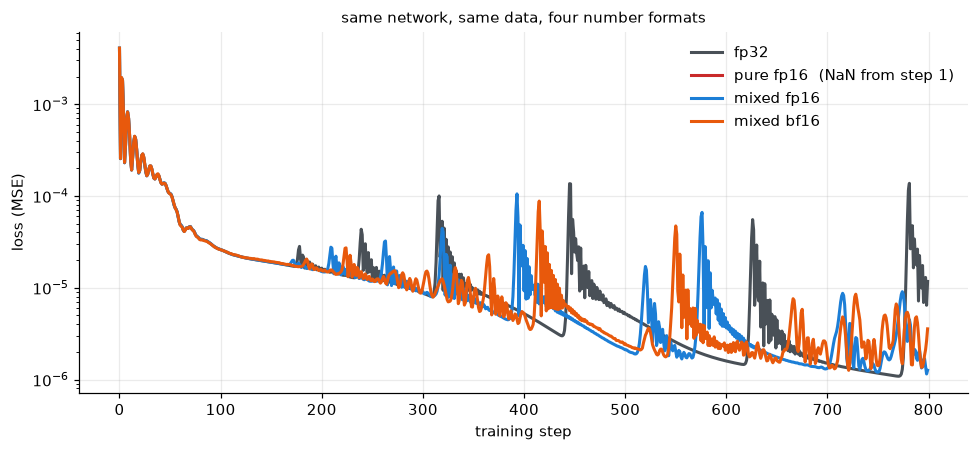

fp32        final loss 1.17e-05   skipped steps 0
pure fp16   final loss nan   skipped steps 0
mixed fp16  final loss 1.26e-06   skipped steps 0
mixed bf16  final loss 3.56e-06   skipped steps 0
PASS - pure fp16 (no master copy) breaks down - NaN loss 
PASS - mixed fp16 trains: loss falls >100x and tracks fp32 (final < 1e-4) | 1.3e-06 vs fp32 1.2e-05
PASS - mixed bf16 trains the same, with no scaler (final < 1e-4) | 3.6e-06
PASS - dynamic scaler skipped few steps in the mixed fp16 run (<5%) | 0 of 800


In [11]:
def make_net(seed=0, d=64, L=6):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(1, d), nn.Tanh(), *[m for _ in range(L) for m in (nn.Linear(d, d), nn.Tanh())], nn.Linear(d, 1))
X = torch.linspace(-3, 3, 512).unsqueeze(1); Y = 0.02 * torch.sin(2 * X)

def train_manual(mode, steps=800, lr=1e-3):
    master = make_net()
    if mode == "pure fp16": master = master.half()
    low = {"mixed fp16": torch.float16, "mixed bf16": torch.bfloat16}.get(mode)
    work = copy.deepcopy(master).to(low) if low else None
    opt = torch.optim.Adam(master.parameters(), lr=lr)
    scaler = DynamicScaler(init=2.0 ** 12, interval=100) if mode == "mixed fp16" else None
    S_trace, skipped, losses = [], 0, []
    for _ in range(steps):
        if mode == "fp32":
            loss = ((master(X) - Y) ** 2).mean(); loss.backward(); opt.step(); opt.zero_grad()
        elif mode == "pure fp16":
            out = master(X.half()); loss = ((out.float() - Y) ** 2).mean(); loss.backward(); opt.step(); opt.zero_grad()
        else:
            for pw, pm in zip(work.parameters(), master.parameters()): pw.data.copy_(pm.data)       # (2) cast: master -> cheap copy
            out = work(X.to(low))                                                                     # (3) forward in low precision
            loss = ((out.float() - Y) ** 2).mean()                                                    # (4) loss in fp32
            S = scaler.scale if scaler else 1.0
            (loss * S).backward()                                                                     # (5) backward on loss x S
            finite = True
            for pw, pm in zip(work.parameters(), master.parameters()):
                pm.grad = pw.grad.float() / S; pw.grad = None                                         # (6) unscale in fp32
                finite &= bool(torch.isfinite(pm.grad).all())
            if scaler: scaler.update(not finite); S_trace.append(S)
            if finite: opt.step()                                                                     # (7) update the MASTER
            else: skipped += 1
            opt.zero_grad()
        losses.append(loss.item())
    return np.array(losses), skipped, S_trace

runs = {m: train_manual(m) for m in ["fp32", "pure fp16", "mixed fp16", "mixed bf16"]}
fig, ax = plt.subplots(figsize=(9, 4.2))
cols = {"fp32": "#495057", "pure fp16": BAD_C, "mixed fp16": HI_C, "mixed bf16": LO_C}
for m, (l, sk, _) in runs.items():
    ax.plot(np.where(np.isfinite(l), l, np.nan), color=cols[m], lw=2, label=f"{m}" + ("  (NaN from step %d)" % int(np.argmax(~np.isfinite(l))) if (~np.isfinite(l)).any() else ""))
ax.set_yscale("log"); ax.set_xlabel("training step"); ax.set_ylabel("loss (MSE)"); ax.legend(frameon=False)
ax.set_title("same network, same data, four number formats", fontsize=10); plt.tight_layout(); plt.show()
for m, (l, sk, _) in runs.items(): print(f"{m:11s} final loss {l[-1]:.2e}   skipped steps {sk}")
f = {m: r[0][-1] for m, r in runs.items()}
check("pure fp16 (no master copy) breaks down - NaN loss", not np.isfinite(runs["pure fp16"][0]).all())
check("mixed fp16 trains: loss falls >100x and tracks fp32 (final < 1e-4)", runs["mixed fp16"][0][-1] < runs["mixed fp16"][0][0] / 100 and f["mixed fp16"] < 1e-4, f"{f['mixed fp16']:.1e} vs fp32 {f['fp32']:.1e}")
check("mixed bf16 trains the same, with no scaler (final < 1e-4)", f["mixed bf16"] < 1e-4, f"{f['mixed bf16']:.1e}")
check("dynamic scaler skipped few steps in the mixed fp16 run (<5%)", runs["mixed fp16"][1] < 40, f"{runs['mixed fp16'][1]} of 800")

**How to read this honestly:**
- the loss spikes (in *every* curve, fp32 included) are Adam at `lr = 1e-3` on a tiny target - not a precision effect.
- *pure fp16* diverges (the NaN is the Adam `0/0` from Step 3). Master weights are **not optional**.
- the mixed runs and fp32 all fit the curve. The tiny differences between their final losses are run-to-run noise, **not** "mixed precision is more accurate". The claim is only *"it keeps up with fp32"*.
- On this small network loss scaling made little difference to the outcome (Adam rescales updates by gradient size, which hides the effect). Step 4 showed where it **does** matter: gradients themselves being flushed to zero. In big networks that is common.
- Speed is not measured: the speed-up comes from GPU tensor cores / matrix engines, and a CPU laptop run says nothing about it.

## Step 8 - What it saves, and what it does *not*

A common surprise: **with `torch.autocast`, the weights, gradients and optimizer states are all still fp32.** The saving is mostly in *activations* - the intermediate tensors the forward pass keeps for backward, which dominate memory for large batches/sequences. We measure it with PyTorch's `saved_tensors_hooks`, which sees exactly the tensors kept for backward:

In [12]:
def saved_bytes(model, x, autocast_dtype=None):
    seen, total = set(), 0
    def pack(t):
        nonlocal total
        key = (t.untyped_storage().data_ptr(), t.dtype, tuple(t.shape), t.stride())
        if key not in seen: seen.add(key); total += t.numel() * t.element_size()
        return t
    ctx = torch.autocast("cpu", dtype=autocast_dtype) if autocast_dtype else torch.autocast("cpu", enabled=False)
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t), ctx:
        out = model(x); loss = out.float().pow(2).mean()
    loss.backward(); return total

torch.manual_seed(0)
big = nn.Sequential(*[m for _ in range(8) for m in (nn.Linear(512, 512), nn.GELU())]); xb = torch.randn(256, 512)
b32 = saved_bytes(big, xb); b16 = saved_bytes(big, xb, torch.bfloat16)
print(f"tensors kept for backward:  fp32 {b32 / 2**20:.1f} MiB   autocast bf16 {b16 / 2**20:.1f} MiB   ratio {b16 / b32:.2f}")
check("autocast keeps clearly less for backward than fp32 (ratio < 0.75)", b16 / b32 < 0.75, f"ratio {b16 / b32:.2f}")

# params / grads / Adam state under autocast
m = copy.deepcopy(big); o = torch.optim.Adam(m.parameters())
with torch.autocast("cpu", dtype=torch.bfloat16): l = m(xb).float().pow(2).mean()
l.backward(); o.step()
nbytes = lambda ts: sum(t.numel() * t.element_size() for t in ts)
P = nbytes(m.parameters()); G = nbytes(p.grad for p in m.parameters()); O = nbytes(v for s in o.state.values() for v in s.values() if torch.is_tensor(v) and v.dim() > 0)
print(f"under autocast:  weights {P / 2**20:.1f} MiB (dtype {next(m.parameters()).dtype})   grads {G / 2**20:.1f} MiB   Adam state {O / 2**20:.1f} MiB")
check("under autocast, weights, grads and Adam state are all still fp32 (4 bytes/param, state = 2x)", next(m.parameters()).dtype == torch.float32 and G == P and O == 2 * P)

tensors kept for backward:  fp32 15.5 MiB   autocast bf16 8.0 MiB   ratio 0.52
PASS - autocast keeps clearly less for backward than fp32 (ratio < 0.75) | ratio 0.52


under autocast:  weights 8.0 MiB (dtype torch.float32)   grads 8.0 MiB   Adam state 16.0 MiB
PASS - under autocast, weights, grads and Adam state are all still fp32 (4 bytes/param, state = 2x) 


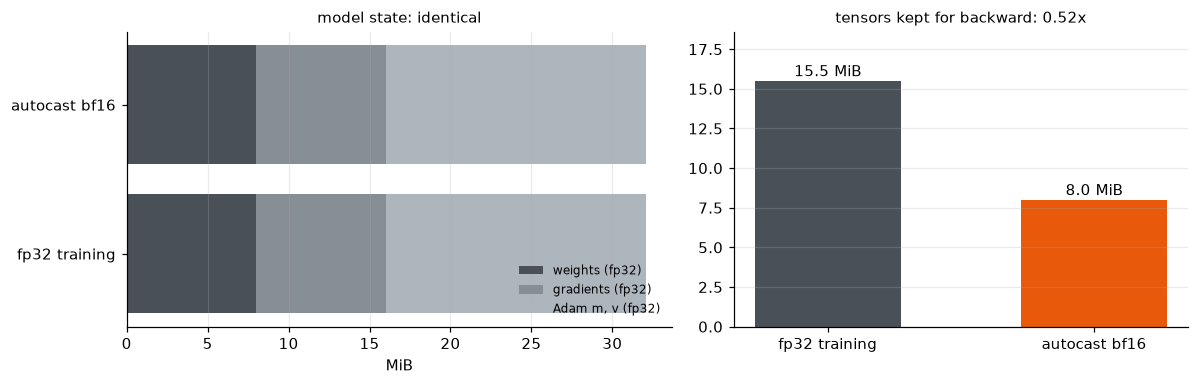

PASS - model state (weights + grads + Adam) is byte-identical between fp32 and autocast | 32.1 MiB both


In [13]:
def model_state_bytes(autocast_dtype):
    m = copy.deepcopy(big); o = torch.optim.Adam(m.parameters())
    ctx = torch.autocast("cpu", dtype=autocast_dtype) if autocast_dtype else torch.autocast("cpu", enabled=False)
    with ctx: l = m(xb).float().pow(2).mean()
    l.backward(); o.step()
    return (nbytes(m.parameters()), nbytes(p.grad for p in m.parameters()), nbytes(v for s in o.state.values() for v in s.values() if torch.is_tensor(v) and v.dim() > 0))
st32, stmx = model_state_bytes(None), model_state_bytes(torch.bfloat16)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axs[0]; labs = ["fp32 training", "autocast bf16"]
for r, st in enumerate([st32, stmx]):
    left = 0
    for v, c, lab in zip(st, ["#495057", "#868e96", "#adb5bd"], ["weights (fp32)", "gradients (fp32)", "Adam m, v (fp32)"]):
        ax.barh(r, v / 2**20, left=left, color=c, label=lab if r == 0 else None); left += v / 2**20
ax.set_yticks([0, 1]); ax.set_yticklabels(labs); ax.set_xlabel("MiB"); ax.set_title("model state: identical", fontsize=10); ax.grid(axis="y", alpha=0); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax = axs[1]
ax.bar([0, 1], [b32 / 2**20, b16 / 2**20], color=["#495057", LO_C], width=0.55); ax.set_xticks([0, 1]); ax.set_xticklabels(["fp32 training", "autocast bf16"])
for i, v in enumerate([b32, b16]): ax.text(i, v / 2**20 + 0.3, f"{v / 2**20:.1f} MiB", ha="center")
ax.set_title(f"tensors kept for backward: {b16 / b32:.2f}x", fontsize=10); ax.set_ylim(0, b32 / 2**20 * 1.2); ax.grid(axis="x", alpha=0)
plt.tight_layout(); plt.show()
check("model state (weights + grads + Adam) is byte-identical between fp32 and autocast", st32 == stmx, f"{sum(st32) / 2**20:.1f} MiB both")

Some frameworks (e.g. DeepSpeed/ZeRO-style *fp16 model + fp32 optimizer*) go further and store the **model itself** in fp16, keeping fp32 master copies only inside the optimizer: per parameter `2 (fp16 weights) + 2 (fp16 grads) + 12 (fp32 master + Adam m, v) = 16 bytes` (ZeRO paper, Rajbhandari et al. 2020) - the same 16 bytes as plain fp32 + Adam (`4 + 4 + 8`). So *mixed precision does not reduce the memory of model state; its win is activation memory, memory traffic and matmul speed.* (Sharding or 8-bit optimizers are what shrink the 16 bytes.)

## Step 9 - PyTorch recipes (copy-paste, each executed here)

Everything above reduces to a few lines. **Each recipe below is a real function that runs on this CPU and is checked to train.**

First, the shared toy problem and an assertion helper:

In [14]:
def toy(seed=0):
    torch.manual_seed(seed)
    model = nn.Sequential(nn.Linear(16, 64), nn.GELU(), nn.Linear(64, 64), nn.GELU(), nn.Linear(64, 1))
    x = torch.randn(512, 16); y = (x[:, :1] * 2 - x[:, 1:2]) + 0.1 * torch.randn(512, 1)
    return model, x, y

def loss_ok(name, losses):
    check(f"recipe '{name}': loss falls >5x and is finite", np.isfinite(losses).all() and losses[-1] < losses[0] / 5, f"{losses[0]:.3f} -> {losses[-1]:.4f}")

### Recipe 1 - bf16 autocast (simplest; no scaler)
Use this on any hardware that supports bf16 (recent NVIDIA/AMD GPUs, TPUs, Apple silicon, modern CPUs).

In [15]:
def train_bf16(steps=150, device="cpu"):
    model, x, y = toy(); model.to(device); x, y = x.to(device), y.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3)
    losses = []
    for step in range(steps):
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device, dtype=torch.bfloat16):   # ops pick bf16 or fp32 automatically
            pred = model(x)
        loss = nn.functional.mse_loss(pred.float(), y)                    # compute the loss in fp32
        loss.backward()                                                   # no scaling needed for bf16
        opt.step()
        losses.append(loss.item())
    return np.array(losses)
loss_ok("bf16 autocast", train_bf16())

PASS - recipe 'bf16 autocast': loss falls >5x and is finite | 4.884 -> 0.0096


### Recipe 2 - fp16 autocast + `GradScaler`
Use this for fp16 (older GPUs without bf16, or when you specifically want fp16). The scaler is what Step 5 built.

In [16]:
def train_fp16(steps=150, device="cpu"):
    model, x, y = toy(); model.to(device); x, y = x.to(device), y.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3)
    scaler = torch.amp.GradScaler(device)                                 # dynamic loss scaling (Step 5)
    losses = []
    for step in range(steps):
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device, dtype=torch.float16):
            pred = model(x)
        loss = nn.functional.mse_loss(pred.float(), y)
        scaler.scale(loss).backward()                                     # backward on loss * S
        scaler.step(opt)                                                  # unscales, skips the step if inf/NaN found
        scaler.update()                                                   # adapts S
        losses.append(loss.item())
    return np.array(losses), scaler.get_scale()
l16, S_final = train_fp16()
loss_ok("fp16 autocast + GradScaler", l16)
print("final loss scale:", S_final)

PASS - recipe 'fp16 autocast + GradScaler': loss falls >5x and is finite | 4.884 -> 0.0096
final loss scale: 65536.0


### Recipe 3 - with gradient clipping and gradient accumulation
Two things people forget: **clip the *unscaled* gradients** (so call `scaler.unscale_(opt)` first, otherwise you clip `S × gradient`), and divide the loss by the number of accumulation steps. Same code works for bf16 - just drop the scaler lines.

In [17]:
def train_fp16_clip_accum(steps=60, accum=4, device="cpu"):
    model, x, y = toy(); model.to(device); x, y = x.to(device), y.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-3); scaler = torch.amp.GradScaler(device)
    losses = []; chunks = list(zip(x.chunk(accum), y.chunk(accum)))
    for step in range(steps):
        opt.zero_grad(set_to_none=True); total = 0.0
        for xb, yb in chunks:                                             # accumulate over `accum` micro-batches
            with torch.autocast(device_type=device, dtype=torch.float16):
                pred = model(xb)
            loss = nn.functional.mse_loss(pred.float(), yb) / accum
            scaler.scale(loss).backward(); total += loss.item()
        scaler.unscale_(opt)                                              # grads are now the true (unscaled) values
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        losses.append(total)
    return np.array(losses)
loss_ok("fp16 + clipping + accumulation", train_fp16_clip_accum())

# prove that unscale_ really gives the true gradient before clipping
model, x, y = toy(); sc = torch.amp.GradScaler("cpu", init_scale=1024.0)
with torch.autocast("cpu", dtype=torch.float16): l = nn.functional.mse_loss(model(x).float(), y)
sc.scale(l).backward(); g_scaled = model[0].weight.grad.clone(); opt = torch.optim.SGD(model.parameters(), 0.1); sc.unscale_(opt)
check("before unscale_ grads are S x true; after, they are the true gradient", torch.allclose(g_scaled, model[0].weight.grad * 1024.0, rtol=1e-5, atol=0))

PASS - recipe 'fp16 + clipping + accumulation': loss falls >5x and is finite | 4.884 -> 0.0285
PASS - before unscale_ grads are S x true; after, they are the true gradient 


### Recipe 4 - choose the setup per device
bf16 where it is supported, else fp16 + scaler. (This repo has a `device.py` that resolves cpu / cuda / rocm / mps - `HaloDiffusionLLM/src/hale_llm/utils/device.py`; the function below only decides the *dtype* given a device.)

In [18]:
def amp_config(device_type: str):
    """-> (autocast device_type, dtype, use_grad_scaler)"""
    if device_type == "cuda":                                             # NVIDIA and AMD-ROCm both appear as "cuda"
        if torch.cuda.is_available() and torch.cuda.is_bf16_supported(): return "cuda", torch.bfloat16, False
        return "cuda", torch.float16, True
    if device_type == "mps":   return "mps", torch.float16, False        # (check your torch version's mps autocast support)
    return "cpu", torch.bfloat16, False

def train_generic(device_type="cpu", steps=100):
    dev, dtype, use_scaler = amp_config(device_type)
    model, x, y = toy(); opt = torch.optim.AdamW(model.parameters(), lr=3e-3)
    scaler = torch.amp.GradScaler(dev, enabled=use_scaler)                # a disabled scaler is a no-op pass-through
    losses = []
    for _ in range(steps):
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=dev, dtype=dtype):
            pred = model(x)
        loss = nn.functional.mse_loss(pred.float(), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); losses.append(loss.item())
    return np.array(losses)
print("cpu ->", amp_config("cpu"))
loss_ok("device-generic (cpu path)", train_generic("cpu"))

cpu -> ('cpu', torch.bfloat16, False)


PASS - recipe 'device-generic (cpu path)': loss falls >5x and is finite | 4.884 -> 0.0151


Only the **cpu** path of Recipe 4 is executed here; the `cuda`/`mps` branches are the documented patterns and were **not** run on that hardware in this notebook.

### The recipes agree with the by-hand version
Recipes 1-2 use PyTorch's `autocast` + `GradScaler`; Step 7 used our hand-written version. Different problem, so we compare *behaviour*: both reach a loss close to the fp32 run on their own problem.

final loss  fp32 0.0096 | bf16 autocast 0.0096 | fp16 autocast+scaler 0.0096   (noise floor of the data: 0.01)


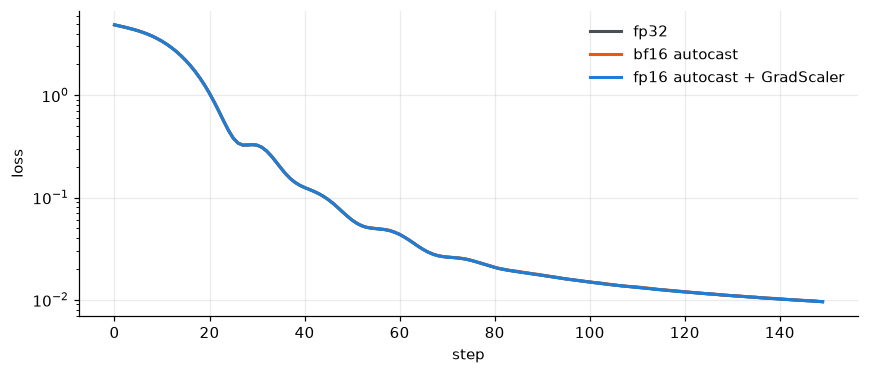

PASS - bf16 and fp16 autocast end within 20% of the fp32 loss | 0.0096 / 0.0096 / 0.0096


In [19]:
def train_fp32_toy(steps=150):
    model, x, y = toy(); opt = torch.optim.AdamW(model.parameters(), lr=3e-3); out = []
    for _ in range(steps):
        opt.zero_grad(); loss = nn.functional.mse_loss(model(x), y); loss.backward(); opt.step(); out.append(loss.item())
    return np.array(out)
a, b, c = train_fp32_toy(), train_bf16(), train_fp16()[0]
print(f"final loss  fp32 {a[-1]:.4f} | bf16 autocast {b[-1]:.4f} | fp16 autocast+scaler {c[-1]:.4f}   (noise floor of the data: 0.01)")
fig, ax = plt.subplots(figsize=(8, 3.5))
for l_, n_, col in [(a, "fp32", "#495057"), (b, "bf16 autocast", LO_C), (c, "fp16 autocast + GradScaler", HI_C)]: ax.plot(l_, label=n_, color=col, lw=2)
ax.set_yscale("log"); ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.legend(frameon=False); plt.tight_layout(); plt.show()
check("bf16 and fp16 autocast end within 20% of the fp32 loss", abs(b[-1] - a[-1]) / a[-1] < 0.2 and abs(c[-1] - a[-1]) / a[-1] < 0.2, f"{a[-1]:.4f} / {b[-1]:.4f} / {c[-1]:.4f}")

### Checklist (the usual mistakes)
- **Keep the loss in fp32:** `mse_loss(pred.float(), y)`; most built-in losses already do it under autocast.
- **bf16 → no scaler. fp16 → always a scaler.**
- **`scaler.unscale_(opt)` before clipping** (Recipe 3), and one `scaler.update()` per optimizer step.
- **Save the scaler with the checkpoint** (`scaler.state_dict()`), or resumed fp16 runs restart at `S = 65536` and skip steps.
- **Do not call `.half()` on the model for training** - that is the "pure fp16" failure of Step 7. Let `autocast` do it per-op.
- **Look for `inf`/`NaN` losses and a collapsing scale** - if `S` keeps halving, something genuinely overflows (a bad learning rate, an unstable layer), it is not the scaler's fault.

In [20]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n, ok, d) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n}")
failed = [n for n, ok, _ in CHECKS if not ok]
print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed")
assert not failed, failed

 #  status  check
 1  PASS    animation 1 written (14 frames)
 2  PASS    fp16-only weight never moves (updates rounded away)
 3  PASS    fp32 master reaches 1.3 (<1e-4 error)
 4  PASS    the fp16 copy follows the master to within half an fp16 step (<=2^-11 * 2)
 5  PASS    animation 2 written
 6  PASS    Adam eps=1e-8 is 0 in fp16, and a squared 1e-4 gradient underflows
 7  PASS    fp32 reference has no zeroed gradients
 8  PASS    late-training case: >20% of fp16 gradients are flushed to 0 without scaling
 9  PASS    loss scaling removes almost all of them (<2%) and stays finite
10  PASS    and gradient error vs fp32 drops by >5x
11  PASS    our DynamicScaler reproduces torch GradScaler's scale on 30 scripted steps
12  PASS    torch skipped the optimizer step exactly on the inf steps
13  PASS    scaled gradients never overflow on a step that was actually applied
14  PASS    only a small fraction of steps are skipped (<15%)
15  PASS    S follows the shrinking safe value down by >4x (i

## Takeaways

1. **Mixed precision = fp32 master weights + a cheap fp16/bf16 working copy.** Heavy compute (matmuls) runs cheap; delicate things (weights, optimizer, loss, reductions) stay precise.
2. **Three problems, three fixes:** tiny updates lost → *fp32 master weights*; tiny gradients underflow → *loss scaling* (dynamic: halve on overflow, grow when safe); precision-critical ops → *autocast keeps them fp32*.
3. **bf16 vs fp16:** bf16 has the range, so no scaler; fp16 needs the scaler.
4. **Honest accounting:** it does not shrink weights/grads/optimizer state (all still fp32 here); it shrinks activations and enables fast low-precision matmuls. Speed was not measured on this CPU.
5. In code it is `torch.autocast` (+ `GradScaler` for fp16) around the forward pass and loss - Step 9.

### Exercises
- In Step 7, replace Adam by plain SGD for *pure fp16* and find the learning rate below which it stops learning (hint: update < half an fp16 gap).
- Change the scaler `interval` in Step 5 to 5 and to 500 - how many steps are skipped vs how large `S` stays?
- Run Step 4 with `torch.bfloat16`: does it need scaling?
- Add `fp8` to Step 6's idea: which ops would you keep in 16-bit? (Hint: see the fp8 formats in notebook 01.)

### Honest limits
CPU only, tiny models, one seed: the *mechanisms* (lost updates, underflowing gradients, the scaler's behaviour, which ops autocast lowers, what memory is saved) are measured, but **speed-ups are not**, and real large-model training adds further effects (fp8 recipes, sharded optimizers, different per-device op lists). The cuda/mps branches of Recipe 4 were not executed.